# Research Question, Objectives and hypothesis Research

Question: Do primary breast tumour and adjacent normal tissues exhibit statistically significant differential expression in key DNA-repair and metabolic pathway genes, and can these expression profiles accurately classify tissue phenotype using machine learning algorithms?

***Project Objectives***

 Data Acquisition & Preprocessing: Acquire raw/count-level RNA-seq gene expression data from public repositories and perform data cleaning, log-transformation, and quality control checks. Differential Expression Analysis: Perform differential gene expression analysis with False Discovery Rate (FDR) p-value adjustments to isolate significantly dysregulated genes. Biological Pathway & Network Analysis: Map top differentially expressed genes onto KEGG/Reactome biological pathways and reconstruct protein interaction sub-networks to identify key functional hubs using NetworkX. Machine Learning & Evaluation: Build and evaluate supervised machine learning classifiers (such as Random Forest and SVM) to predict tumour versus normal samples based on gene expression features

# Stage 1: Data Acquisition

In [6]:

!pip install -q GEOparse

import GEOparse
import pandas as pd
import os

os.makedirs("data", exist_ok=True)

# 1. Download GSE15852 directly from NCBI GEO
gse = GEOparse.get_GEO(geo="GSE15852", destdir="./data", silent=True)

# 2. Build Expression Matrix (Rows = Probe/Gene IDs, Columns = Sample GSM IDs)
expr_matrix = gse.pivot_samples('VALUE')

# Map Affymetrix Probe IDs to official Gene Symbols using platform annotation
gpl = list(gse.gpls.values())[0]
probe_to_gene = gpl.table[['ID', 'Gene Symbol']].dropna()
probe_to_gene = probe_to_gene[probe_to_gene['Gene Symbol'] != '']
# Keep first symbol if multiple are listed (e.g., "BRCA1 /// NBR2" -> "BRCA1")
probe_to_gene['Gene_Symbol'] = probe_to_gene['Gene Symbol'].apply(lambda x: str(x).split('///')[0].strip())

expr_with_gene = expr_matrix.merge(probe_to_gene[['ID', 'Gene_Symbol']], left_index=True, right_on='ID')
expr_with_gene = expr_with_gene.drop(columns=['ID']).set_index('Gene_Symbol')

# Save expression matrix
expr_with_gene.to_csv("data/expression_matrix.csv")

# 3. Build Sample Metadata Table (metadata.csv)
meta_records = []
for gsm_name, gsm in gse.gsms.items():
    title = gsm.metadata.get('title', [''])[0]
    source = gsm.metadata.get('source_name_ch1', [''])[0]
    chars = " | ".join(gsm.metadata.get('characteristics_ch1', []))

    # Determine Tumor vs Normal label
    condition = "Normal" if "normal" in (title + source + chars).lower() else "Tumor"
    # Extract patient pairing ID (e.g., patient number from title)
    patient_id = "".join([c for c in title if c.isdigit()])

    meta_records.append({
        "sample_id": gsm_name,
        "sample_title": title,
        "patient_id": f"Patient_{patient_id}" if patient_id else gsm_name,
        "condition": condition,
        "label": 1 if condition == "Tumor" else 0,
        "source_tissue": source
    })

metadata_df = pd.DataFrame(meta_records)
metadata_df.to_csv("data/metadata.csv", index=False)

# 4. Print Basic Sample-Count Table (Required Evidence)
print("Expression Matrix Shape (Genes x Samples):", expr_with_gene.shape)
print("\nSample-Count Table:")
print(metadata_df['condition'].value_counts().rename_axis('Tissue Type').reset_index(name='Sample Count'))
print("\nUnique Patients:", metadata_df['patient_id'].nunique())


Expression Matrix Shape (Genes x Samples): (21225, 86)

Sample-Count Table:
  Tissue Type  Sample Count
0      Normal            43
1       Tumor            43

Unique Patients: 43


In [ ]:
import pandas as pd

# Load the matrix you already generated in Colab (or re-save it compressed)
expr_with_gene.round(4).to_csv("data/expression_matrix.csv.gz", compression="gzip")
print("Saved compressed expression_matrix.csv.gz!")

Saved compressed expression_matrix.csv.gz!


# Stage 2. Loading the Dataset

In [ ]:
import os
import shutil
import pandas as pd
from google.colab import files

os.makedirs("data", exist_ok=True)

# 1. Explicitly prompt for the compressed expression matrix file
if not os.path.exists("data/expression_matrix.csv.gz"):
    print("Step 1/2 — Upload 'expression_matrix.csv.gz':")
    uploaded_expr = files.upload()
    for filename in uploaded_expr.keys():
        shutil.move(filename, f"data/{filename}")

# 2. Explicitly prompt for the metadata file
if not os.path.exists("data/metadata.csv"):
    print("\nStep 2/2 — Upload 'metadata.csv':")
    uploaded_meta = files.upload()
    for filename in uploaded_meta.keys():
        shutil.move(filename, f"data/{filename}")

# Load authoritative dataset and metadata (pandas reads .csv.gz automatically)
expr_df = pd.read_csv("data/expression_matrix.csv.gz", index_col=0)
metadata_df = pd.read_csv("data/metadata.csv")

print(f"\nExpression Matrix Shape (Genes x Samples): {expr_df.shape}")
print(f"Metadata Shape (Samples x Attributes): {metadata_df.shape}")
print("\nSample-Count Table:")
print(metadata_df['condition'].value_counts().rename_axis('Tissue Type').reset_index(name='Sample Count'))
print(f"\nUnique Patient Pairs: {metadata_df['patient_id'].nunique()}")


Expression Matrix Shape (Genes x Samples): (21225, 86)
Metadata Shape (Samples x Attributes): (86, 6)

Sample-Count Table:
  Tissue Type  Sample Count
0      Normal            43
1       Tumor            43

Unique Patient Pairs: 43


# Stage 3. Preprocessing and quality control
This notebook uses Group 10's expression and metadata exports for GEO GSE15852, an Affymetrix GPL96 breast tumour and patient-matched normal tissue study. The acquisition notebook maps probe sets to source gene symbols and keeps the first listed annotation where a probe has multiple symbols. Probe IDs are absent from the supplied matrix. The values are processed signal intensities. A raw-count export is inapplicable.

Run from the repository root or its notebooks folder. In Colab, upload both supplied CSVs to the session working directory or place the paired exports under data/ using Stage 2. The code also recognizes the local nested expression file. Keep both input files from the same acquisition run. Saved evidence is written to data/person2/.

In [ ]:
from collections import Counter
import csv
import gzip
import hashlib
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

input_pairs = [
    (root / "expression_matrix.csv" / "expression_matrix.csv", root / "metadata.csv"),
    (root / "expression_matrix.csv", root / "metadata.csv"),
    (root / "data" / "expression_matrix.csv", root / "data" / "metadata.csv"),
    (root / "data" / "expression_matrix.csv.gz", root / "data" / "metadata.csv"),
]
inputs = next((pair for pair in input_pairs if all(path.is_file() for path in pair)), None)
if inputs is None:
    raise FileNotFoundError("Place the expression matrix and metadata together as described above.")
expression_file, metadata_file = inputs
output_dir = root / "data" / "person2"

def read_csv_checked(path):
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, mode="rt", encoding="utf-8-sig", newline="") as source:
        header = next(csv.reader(source))
    duplicates = [name for name, count in Counter(header).items() if count > 1]
    if duplicates:
        raise ValueError(f"Duplicate columns in {path.name}: {duplicates}")
    return pd.read_csv(path, dtype=str, keep_default_na=False)

raw = read_csv_checked(expression_file)
metadata = read_csv_checked(metadata_file)
for path in inputs:
    print(f"{path.relative_to(root)} | SHA-256 {hashlib.sha256(path.read_bytes()).hexdigest()}")

data/expression_matrix.csv | SHA-256 91460023a9110eb85ec707a1aab7aa2f2f3cdca224188163e674d4e2c28ccec9
data/metadata.csv | SHA-256 a8f949a4bac6efc6b81b74a491989b1585535e511c60ca85da00d40d05220556


# Sample and expression checks
The expression header defines sample order. We require a one-to-one match to metadata, validate the tissue labels and verify that each patient contributes exactly one sample per class. Invalid values or mismatched IDs stop the run for review. This avoids hidden sample losses or imputation



In [7]:
required = ["sample_id", "sample_title", "patient_id", "condition", "label", "source_tissue"]
if not set(required).issubset(metadata) or raw.columns[0] != "Gene_Symbol":
    raise ValueError("Required metadata fields or Gene_Symbol header are missing.")

metadata = metadata.apply(lambda col: col.str.strip())
sample_ids = pd.Index(raw.columns[1:], name="sample_id")
metadata_missing = int(metadata[required].eq("").sum().sum())
metadata_duplicates = int(metadata["sample_id"].duplicated().sum())
if metadata_missing or metadata_duplicates:
    raise ValueError(f"Metadata has {metadata_missing} blank required cells and {metadata_duplicates} duplicate IDs.")

expression_only = sample_ids.difference(metadata["sample_id"])
metadata_only = pd.Index(metadata["sample_id"]).difference(sample_ids)
if len(expression_only) or len(metadata_only):
    raise ValueError(f"Unmatched IDs: expression={list(expression_only)}, metadata={list(metadata_only)}")
metadata = metadata.set_index("sample_id").loc[sample_ids]
if not metadata["condition"].map({"Normal": "0", "Tumor": "1"}).eq(metadata["label"]).all():
    raise ValueError("Condition and binary label disagree.")
expected_title = metadata["condition"].map({"Normal": "normal", "Tumor": "cancer"})
expected_id = "Patient_" + metadata["sample_title"].str.extract(r"(?i)BC(\d+)[NT]$", expand=False)
expected_suffix = metadata["condition"].map({"Normal": "N", "Tumor": "T"})
if not (metadata["sample_title"].str.split().str[0].str.lower().eq(expected_title)
        & metadata["sample_title"].str[-1].eq(expected_suffix)
        & metadata["patient_id"].eq(expected_id)).all():
    raise ValueError("Metadata conditions or patient IDs disagree with the sample titles.")
pair_table = pd.crosstab(metadata["patient_id"], metadata["condition"]).reindex(
    columns=["Normal", "Tumor"], fill_value=0
)
if not pair_table.eq(1).all().all():
    raise ValueError("Expected one Normal and one Tumor sample per patient.")

symbols = raw["Gene_Symbol"].str.strip()
valid_symbol = ~symbols.str.upper().isin(["", "---", "NA", "N/A", "NULL", "NAN"])
input_values = raw.iloc[:, 1:].apply(lambda col: col.str.strip())
missing_mask = input_values.isin(["", "NA", "N/A", "NaN", "nan", "null", "NULL"])
values = input_values.mask(missing_mask).apply(pd.to_numeric, errors="coerce")
missing_count = int(missing_mask.sum().sum())
nonnumeric_count = int((values.isna() & ~missing_mask).sum().sum())
infinite_count = int(np.isinf(values.to_numpy()).sum())
negative_count = int(values.lt(0).sum().sum())
if any((missing_count, nonnumeric_count, infinite_count, negative_count)):
    raise ValueError(f"Review missing={missing_count}, nonnumeric={nonnumeric_count}, "
                     f"infinite={infinite_count}, negative={negative_count} expression cells.")

values.index = pd.Index(symbols, name="Gene_Symbol")
exact_rows = int(values.reset_index().duplicated().sum())
duplicate_profiles = int(values.T.duplicated().sum())
print(f"Matched samples: {len(sample_ids)}. Complete patient pairs: {len(pair_table)}.")
print(metadata["condition"].value_counts().to_string())
print(f"Input intensities range from {values.min().min():.4g} to {values.max().max():.4g}.")
print(f"Exact duplicate sample profiles: {duplicate_profiles}. Exact duplicate rows: {exact_rows}.")

Matched samples: 86. Complete patient pairs: 43.
condition
Normal    43
Tumor     43
Input intensities range from 0.4325 to 1.904e+04.
Exact duplicate sample profiles: 0. Exact duplicate rows: 0.


# Gene-level filtering and transformation
Remove rows with blank or placeholder symbols and drop exact duplicates with the same symbol and intensity profile. Combine the remaining rows sharing a symbol by their per-sample median on the supplied intensity scale. The median gives each source row equal weight and reduces sensitivity to extreme probe signals. It is a practical gene-level summary and can obscure probe-specific or isoform-specific differences. Retain the source symbol text, including legacy names, for downstream mapping.

Apply a zero-variance filter to remove genes that are constant across all 86 samples. Avoid an arbitrary low-intensity threshold because the input lacks probe detection calls. Then apply the fixed, element-wise transform log2(intensity + 1) to compress the right tail. No across-sample normalization or label-driven feature selection is fitted here. Use this logged matrix directly for EDA and exploratory paired microarray analysis. For ML, keep both samples from a patient in the same split and fit any further scaling or feature selection inside training folds.

In [8]:
valid_rows = values.loc[valid_symbol.to_numpy()]
distinct_rows = valid_rows.loc[~valid_rows.reset_index().duplicated().to_numpy()]
probe_counts = distinct_rows.groupby(level=0, sort=False).size()
gene_intensity = distinct_rows.groupby(level=0, sort=False).median()
constant = gene_intensity.nunique(axis=1).le(1)
kept = gene_intensity.loc[~constant]
clean_expression = np.log2(kept + 1)

row_action = np.full(len(raw), "retained_single_symbol_row", dtype=object)
row_action[~valid_symbol.to_numpy()] = "excluded_missing_symbol"
valid_positions = np.flatnonzero(valid_symbol.to_numpy())
exact_duplicate_mask = valid_rows.reset_index().duplicated().to_numpy()
row_action[valid_positions[exact_duplicate_mask]] = "excluded_exact_duplicate_row"
distinct_positions = valid_positions[~exact_duplicate_mask]
row_action[distinct_positions[distinct_rows.index.isin(probe_counts[probe_counts.gt(1)].index)]] = (
    "combined_by_symbol_median"
)
row_action[distinct_positions[distinct_rows.index.isin(constant[constant].index)]] = (
    "excluded_constant_gene"
)
row_record = pd.DataFrame({
    "input_csv_line": np.arange(2, len(raw) + 2),
    "Gene_Symbol": symbols,
    "action": row_action,
    "retained_gene_source_rows": symbols.map(probe_counts).astype("Int64"),
})

summary = pd.DataFrame([
    ("Expression rows (probe-derived rows before, unique genes after)", len(raw), len(clean_expression)),
    ("Distinct non-placeholder gene symbols", symbols[valid_symbol].nunique(), len(clean_expression)),
    ("Samples", len(sample_ids), clean_expression.shape[1]),
    ("Normal samples", int(metadata.condition.eq("Normal").sum()), int(metadata.condition.eq("Normal").sum())),
    ("Tumor samples", int(metadata.condition.eq("Tumor").sum()), int(metadata.condition.eq("Tumor").sum())),
    ("Complete patient pairs", len(pair_table), len(pair_table)),
    ("Missing expression cells", missing_count, int(clean_expression.isna().sum().sum())),
    ("Nonnumeric expression cells", nonnumeric_count, 0),
    ("Infinite or negative expression cells", infinite_count + negative_count, 0),
    ("Blank required metadata fields", metadata_missing, 0),
    ("Unmatched sample IDs across files", len(expression_only) + len(metadata_only), 0),
    ("Duplicate sample IDs", metadata_duplicates, 0),
    ("Exact duplicate sample profiles", duplicate_profiles, int(clean_expression.T.duplicated().sum())),
    ("Exact duplicate expression rows with the same symbol", exact_rows, 0),
    ("Extra valid rows with a repeated gene symbol", int(symbols[valid_symbol].duplicated().sum()), 0),
    ("Missing or placeholder gene symbols", int((~valid_symbol).sum()), 0),
], columns=["Check", "Before", "After"])
changes = pd.DataFrame([
    ("Exclude blank or placeholder gene symbols", len(values) - len(valid_rows)),
    ("Exclude exact duplicate rows (same symbol and all intensities)", len(valid_rows) - len(distinct_rows)),
    ("Collapse surplus rows by per-sample same-symbol median", len(distinct_rows) - len(gene_intensity)),
    ("Exclude constant gene-level rows", int(constant.sum())),
    ("Samples excluded", 0),
], columns=["Operation", "Rows_or_samples_affected"])
assert clean_expression.index.is_unique and clean_expression.columns.equals(metadata.index)
assert np.isfinite(clean_expression.to_numpy()).all()
assert len(clean_expression) == len(raw) - changes.loc[:3, "Rows_or_samples_affected"].sum()
display(summary, changes)

,Check,Before,After
0,"Expression rows (probe-derived rows before, un...",21225,13237
1,Distinct non-placeholder gene symbols,13237,13237
2,Samples,86,86
3,Normal samples,43,43
4,Tumor samples,43,43
5,Complete patient pairs,43,43
6,Missing expression cells,0,0
7,Nonnumeric expression cells,0,0
8,Infinite or negative expression cells,0,0
9,Blank required metadata fields,0,0


,Operation,Rows_or_samples_affected
0,Exclude blank or placeholder gene symbols,0
1,Exclude exact duplicate rows (same symbol and ...,0
2,Collapse surplus rows by per-sample same-symbo...,7988
3,Exclude constant gene-level rows,0
4,Samples excluded,0


# Sample quality screen
Compare sample median intensity on the supplied scale and median Spearman correlation to all other expression profiles. Flag medians outside the pooled 1.5×IQR fences or correlations below their lower fence. These are descriptive screens. A flagged sample can reflect biology or technical variation. Review the source and batch records before deciding on exclusion. Retain all pairs for this handover.

Median intensity fence: -79.47 to 1044.83
Lower correlation fence: 0.788
Flagged samples: 5. Samples excluded: 0.
Lowest median correlation: GSM398100 (0.676).


,patient_id,condition,median_input_intensity,median_log2_gene_expression,median_spearman_to_other_samples,intensity_flag,correlation_flag,review_flag
sample_id,,,,,,,,
GSM398074,Patient_0043,Normal,333.232,8.485238,0.775306,False,True,True
GSM398100,Patient_0147,Normal,376.186,8.619574,0.676328,False,True,True
GSM398123,Patient_0165,Tumor,320.767,8.440172,0.776082,False,True,True
GSM398154,Patient_0191,Normal,583.404,9.312713,0.768804,False,True,True
GSM398155,Patient_0191,Tumor,558.374,9.265395,0.758818,False,True,True


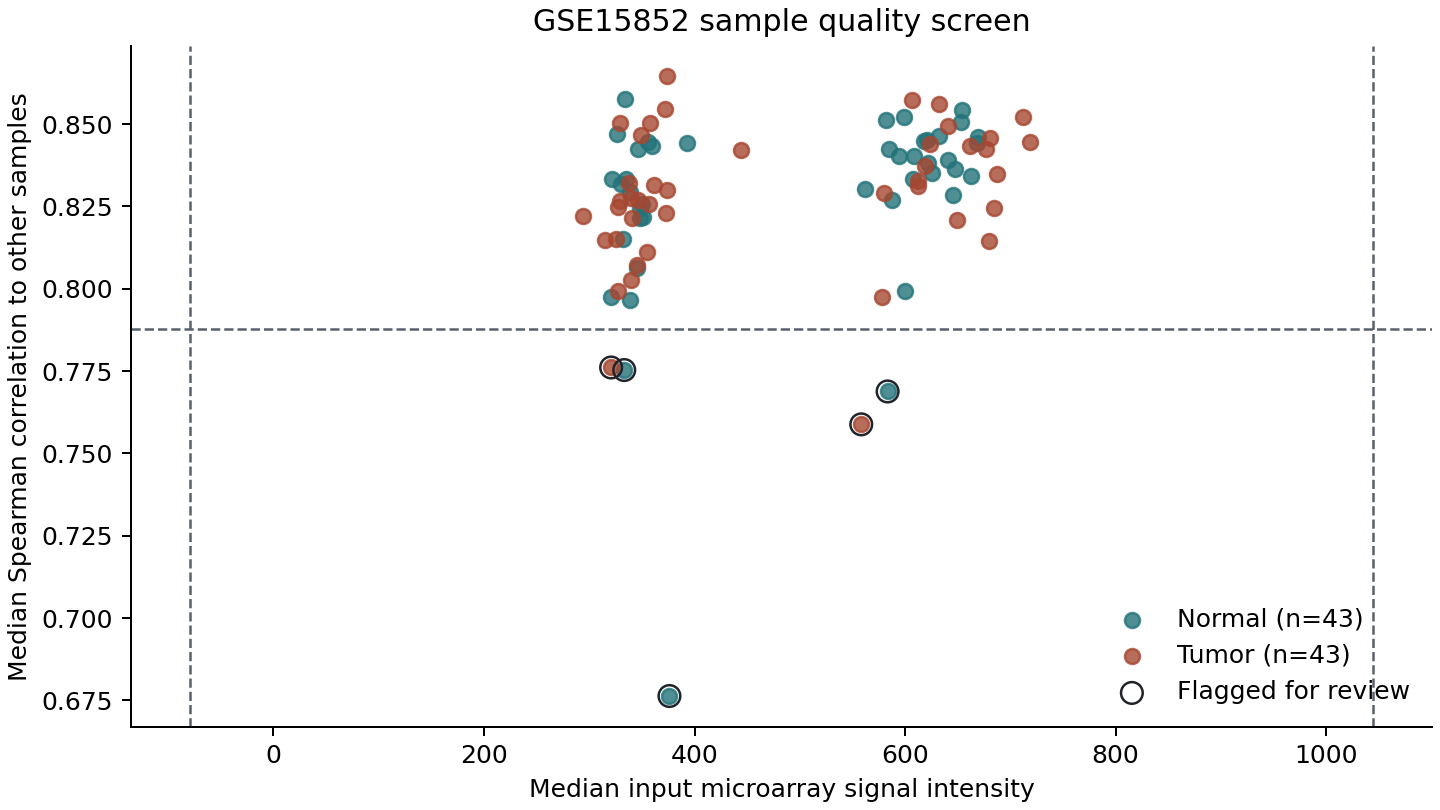

In [9]:
qc = metadata[["patient_id", "condition"]].copy()
qc["median_input_intensity"] = values.median(axis=0)
qc["median_log2_gene_expression"] = clean_expression.median(axis=0)
correlations = clean_expression.corr(method="spearman")
correlations = correlations.mask(np.eye(len(correlations), dtype=bool))
qc["median_spearman_to_other_samples"] = correlations.median(axis=0)

def iqr_fences(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

intensity_low, intensity_high = iqr_fences(qc["median_input_intensity"])
correlation_low, _ = iqr_fences(qc["median_spearman_to_other_samples"])
qc["intensity_flag"] = ~qc["median_input_intensity"].between(intensity_low, intensity_high)
qc["correlation_flag"] = qc["median_spearman_to_other_samples"].lt(correlation_low)
qc["review_flag"] = qc["intensity_flag"] | qc["correlation_flag"]
print(f"Median intensity fence: {intensity_low:.2f} to {intensity_high:.2f}")
print(f"Lower correlation fence: {correlation_low:.3f}")
print(f"Flagged samples: {int(qc.review_flag.sum())}. Samples excluded: 0.")
lowest = qc["median_spearman_to_other_samples"].idxmin()
print(f"Lowest median correlation: {lowest} ({qc.at[lowest, 'median_spearman_to_other_samples']:.3f}).")
display(qc.loc[qc.review_flag])

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for label, color in [("Normal", "#23737A"), ("Tumor", "#A64731")]:
    group = qc.loc[qc.condition.eq(label)]
    ax.scatter(group["median_input_intensity"], group["median_spearman_to_other_samples"],
               label=f"{label} (n={len(group)})", color=color, alpha=.8)
ax.axhline(correlation_low, linestyle="--", color="#58616B", linewidth=1)
for threshold in [intensity_low, intensity_high]:
    ax.axvline(threshold, linestyle="--", color="#58616B", linewidth=1)
flagged = qc.loc[qc.review_flag]
ax.scatter(flagged["median_input_intensity"], flagged["median_spearman_to_other_samples"],
           facecolors="none", edgecolors="#21252B", s=75, label="Flagged for review")
ax.set(title="GSE15852 sample quality screen",
       xlabel="Median input microarray signal intensity",
       ylabel="Median Spearman correlation to other samples")
ax.legend(loc="lower right", frameon=False)
ax.spines[["right", "top"]].set_visible(False)

output_dir.mkdir(parents=True, exist_ok=True)
figure_path = output_dir / "sample_qc.png"
fig.savefig(figure_path, dpi=180, facecolor="white")
plt.close(fig)
display(Image(filename=str(figure_path), width=760))

# Handover files and interpretation
The clean expression CSV has one row per source gene symbol and one column per GEO sample accession. The clean metadata follows exactly the same sample order and preserves patient, condition and label. The two QC tables record before/after counts and the effect of each rule. The row audit identifies the input CSV line and its action. The sample QC CSV records the screening metrics and flags for every sample.

Flagged observations remain in the data. The processed expression preview cannot establish chip-level quality or distinguish batch effects from tissue biology. A paired sensitivity analysis can help assess whether flagged samples influence downstream conclusions.

In [10]:
clean_expression.to_csv(output_dir / "clean_expression.csv", float_format="%.12g")
metadata.to_csv(output_dir / "clean_metadata.csv")
summary.to_csv(output_dir / "qc_before_after.csv", index=False)
changes.to_csv(output_dir / "qc_changes.csv", index=False)
row_record.to_csv(output_dir / "gene_row_audit.csv", index=False)
qc.to_csv(output_dir / "sample_qc.csv")
print(f"Saved {len(clean_expression):,} unique genes across {len(sample_ids)} samples "
      f"and {len(pair_table)} complete pairs in {output_dir.relative_to(root)}.")

Saved 13,237 unique genes across 86 samples and 43 complete pairs in data/person2.


# Stage 4. Exploratory data analysis
These figures compare logged GSE15852 microarray expression from breast tumours and patient-matched adjacent normal tissue. Inputs are the Stage 3 clean matrix and sample metadata. The optional Stage 3 QC table adds flagged-sample markers to the PCA plot.

Run the notebook from the checkout root or the notebooks folder. In Colab, make the checkout and the Stage 3 inputs available, then set the working directory to the checkout. The plotting functions are shared with the Windows runner in scripts/run_eda.py.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from pathlib import Path

# Fallback implementation of run_eda functions to make the notebook completely self-contained in Colab
expression = clean_expression
metadata = metadata

# Ensure output directory exists
Path("data/person2").mkdir(parents=True, exist_ok=True)

def distribution_plot(expr, meta):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(expr.mean(axis=0), ax=axes[0], kde=True, color='#23737A')
    axes[0].set_title("Distribution of Mean Log2 Expression")
    axes[0].set_xlabel("Log2 Expression")

    # Temporarily reset index to safely access 'sample_id' as a column
    meta_reset = meta.reset_index()
    paired = meta_reset.pivot(index='patient_id', columns='condition', values='sample_id')
    medians_tumor = expr[paired['Tumor']].median()
    medians_normal = expr[paired['Normal']].median()

    for t_val, n_val in zip(medians_tumor, medians_normal):
        axes[1].plot(['Normal', 'Tumor'], [n_val, t_val], color='grey', alpha=0.5)
    axes[1].scatter(['Normal']*len(medians_normal), medians_normal, color='#23737A', zorder=3, label='Normal')
    axes[1].scatter(['Tumor']*len(medians_tumor), medians_tumor, color='#A64731', zorder=3, label='Tumor')
    axes[1].set_title("Matched Patient Median Log2 Expression")
    fig.savefig("data/person2/distribution_plot.png", dpi=150)
    plt.close(fig)
    return "data/person2/distribution_plot.png"

def pca_plot(expr, meta):
    pca = PCA(n_components=2)
    coords = pca.fit_transform(expr.T)
    df_pca = pd.DataFrame(coords, columns=['PC1', 'PC2'], index=expr.columns)
    df_pca = df_pca.join(meta)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='condition', palette={'Normal': '#23737A', 'Tumor': '#A64731'}, ax=ax, s=100)
    ax.set_title(f"PCA of Samples (PC1: {pca.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca.explained_variance_ratio_[1]*100:.1f}%)")
    fig.savefig("data/person2/pca_plot.png", dpi=150)
    plt.close(fig)
    return "data/person2/pca_plot.png"

def heatmap_plot(expr, meta):
    top_30_var = expr.var(axis=1).nlargest(30).index
    df_heat = expr.loc[top_30_var]

    # Scale rows (z-scores)
    df_heat_scaled = df_heat.sub(df_heat.mean(axis=1), axis=0).div(df_heat.std(axis=1), axis=0)

    cg = sns.clustermap(df_heat_scaled, cmap='coolwarm', col_colors=meta['condition'].map({'Normal': '#23737A', 'Tumor': '#A64731'}), figsize=(10, 10))
    cg.savefig("data/person2/heatmap_plot.png", dpi=150)
    plt.close(cg.fig)
    return "data/person2/heatmap_plot.png"

print(f"{expression.shape[0]:,} gene symbols and {expression.shape[1]} samples loaded successfully!")
print(f"{metadata['patient_id'].nunique()} complete patient pairs aligned.")

13,237 gene symbols and 86 samples loaded successfully!
43 complete patient pairs aligned.


# 1. Tumour and normal expression distributions

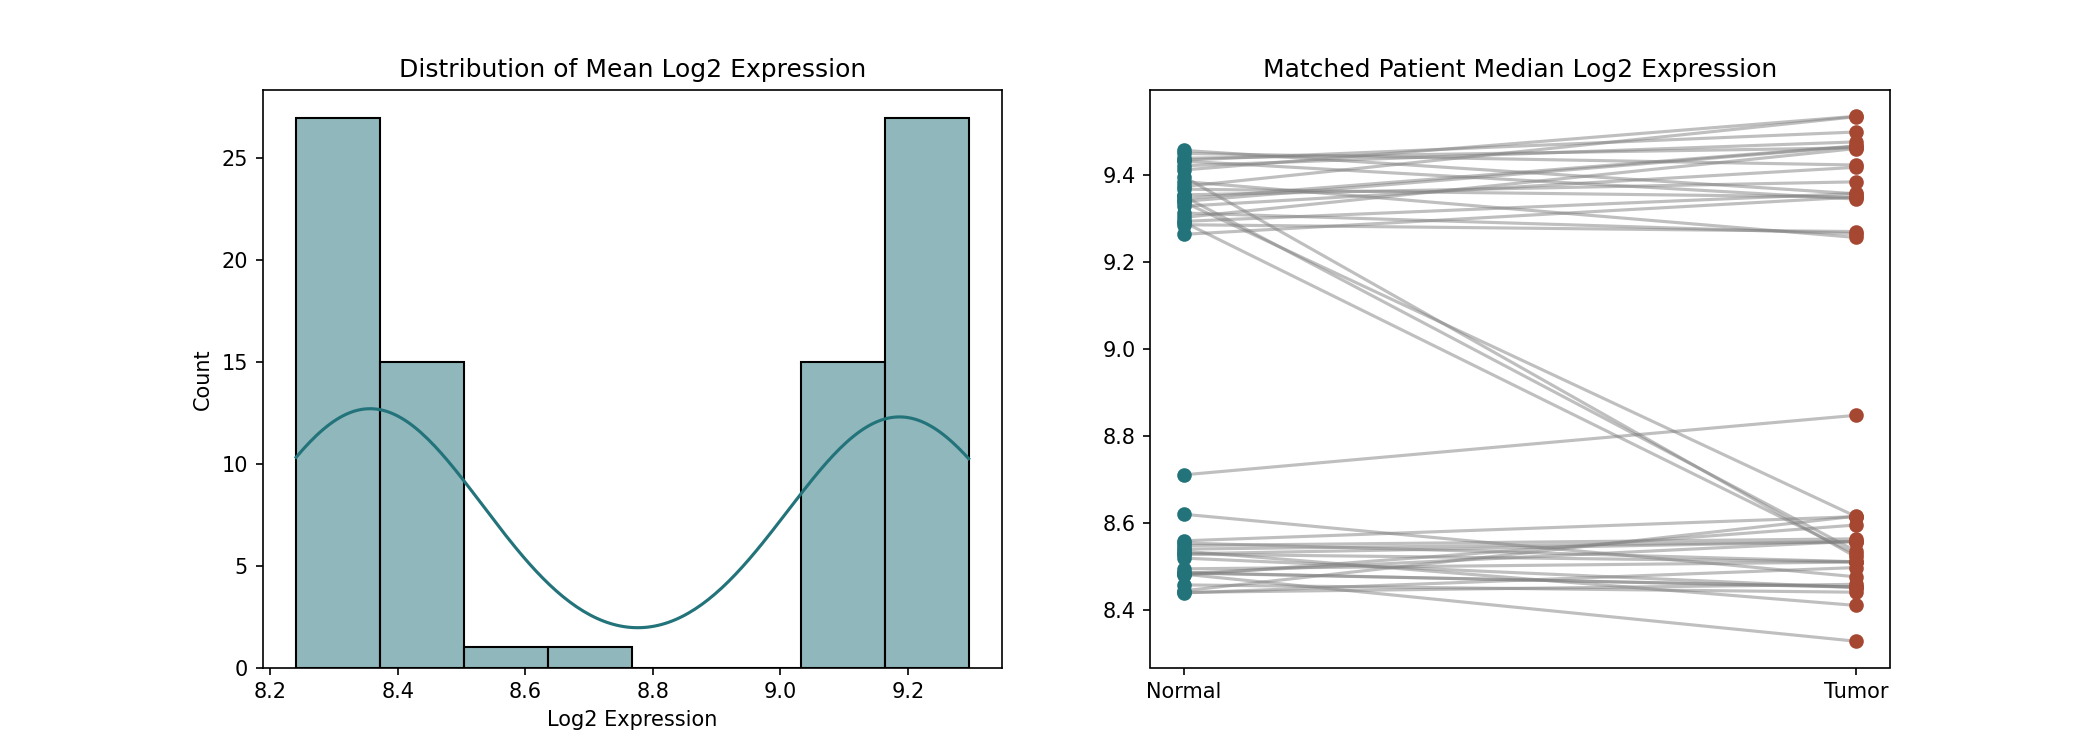

In [18]:
display(Image(filename=str(distribution_plot(expression, metadata)), width=760))

The pooled log-intensity distributions nearly overlap. The right panel links the tumour and normal sample medians for each of the 43 patients. Similar pooled distributions can still contain substantial differences in individual genes.

# 2. Sample PCA

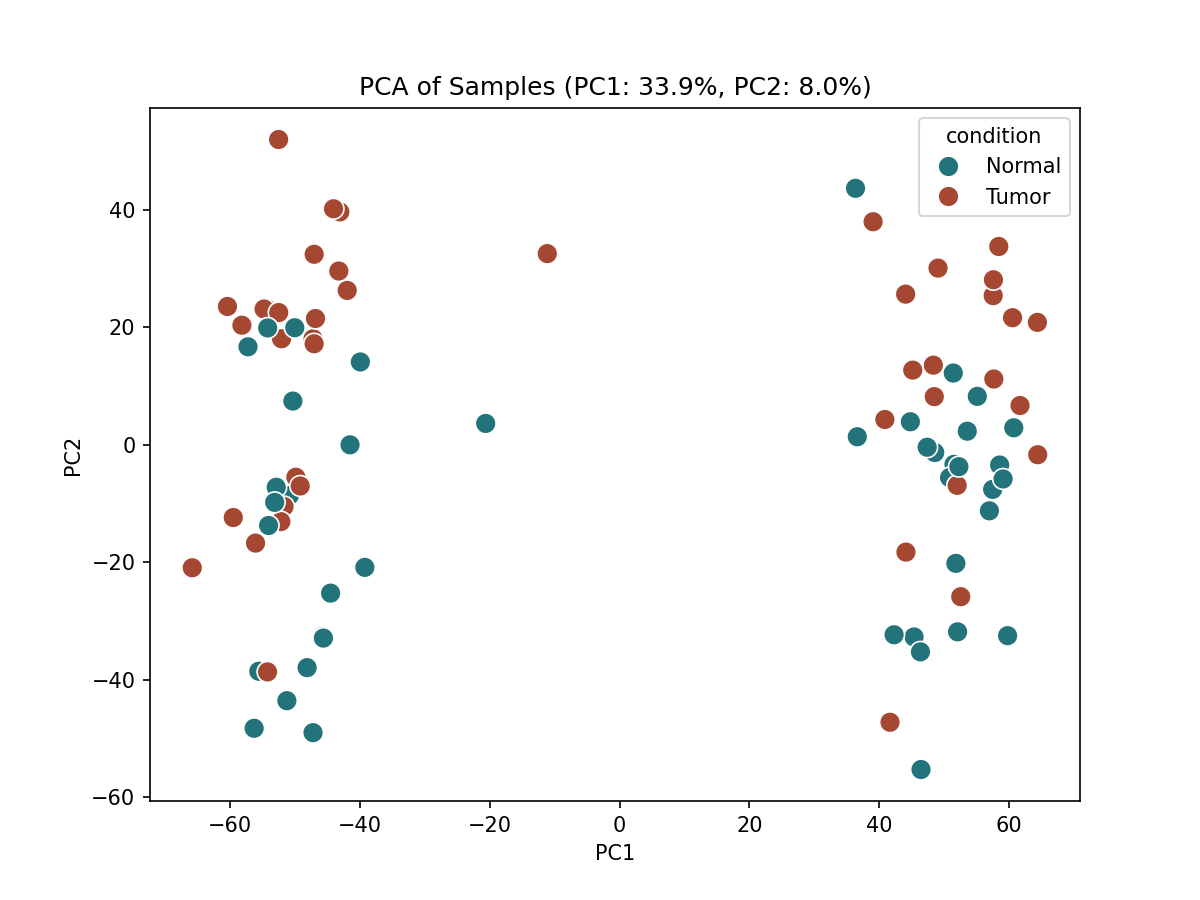

In [19]:
display(Image(filename=str(pca_plot(expression, metadata)), width=760))

PCA uses all 13,237 genes after centering each gene across samples. The variance panel shows that PC1 accounts for 33.85% and PC2 for 8.00%. Both bands along PC1 contain both tissue classes. GSM398074 is the labelled Stage 3 flag farthest from the origin. All 86 samples were retained. Batch information would be needed to investigate a technical explanation for the bands.


# 3. Heatmap of the 30 most variable genes

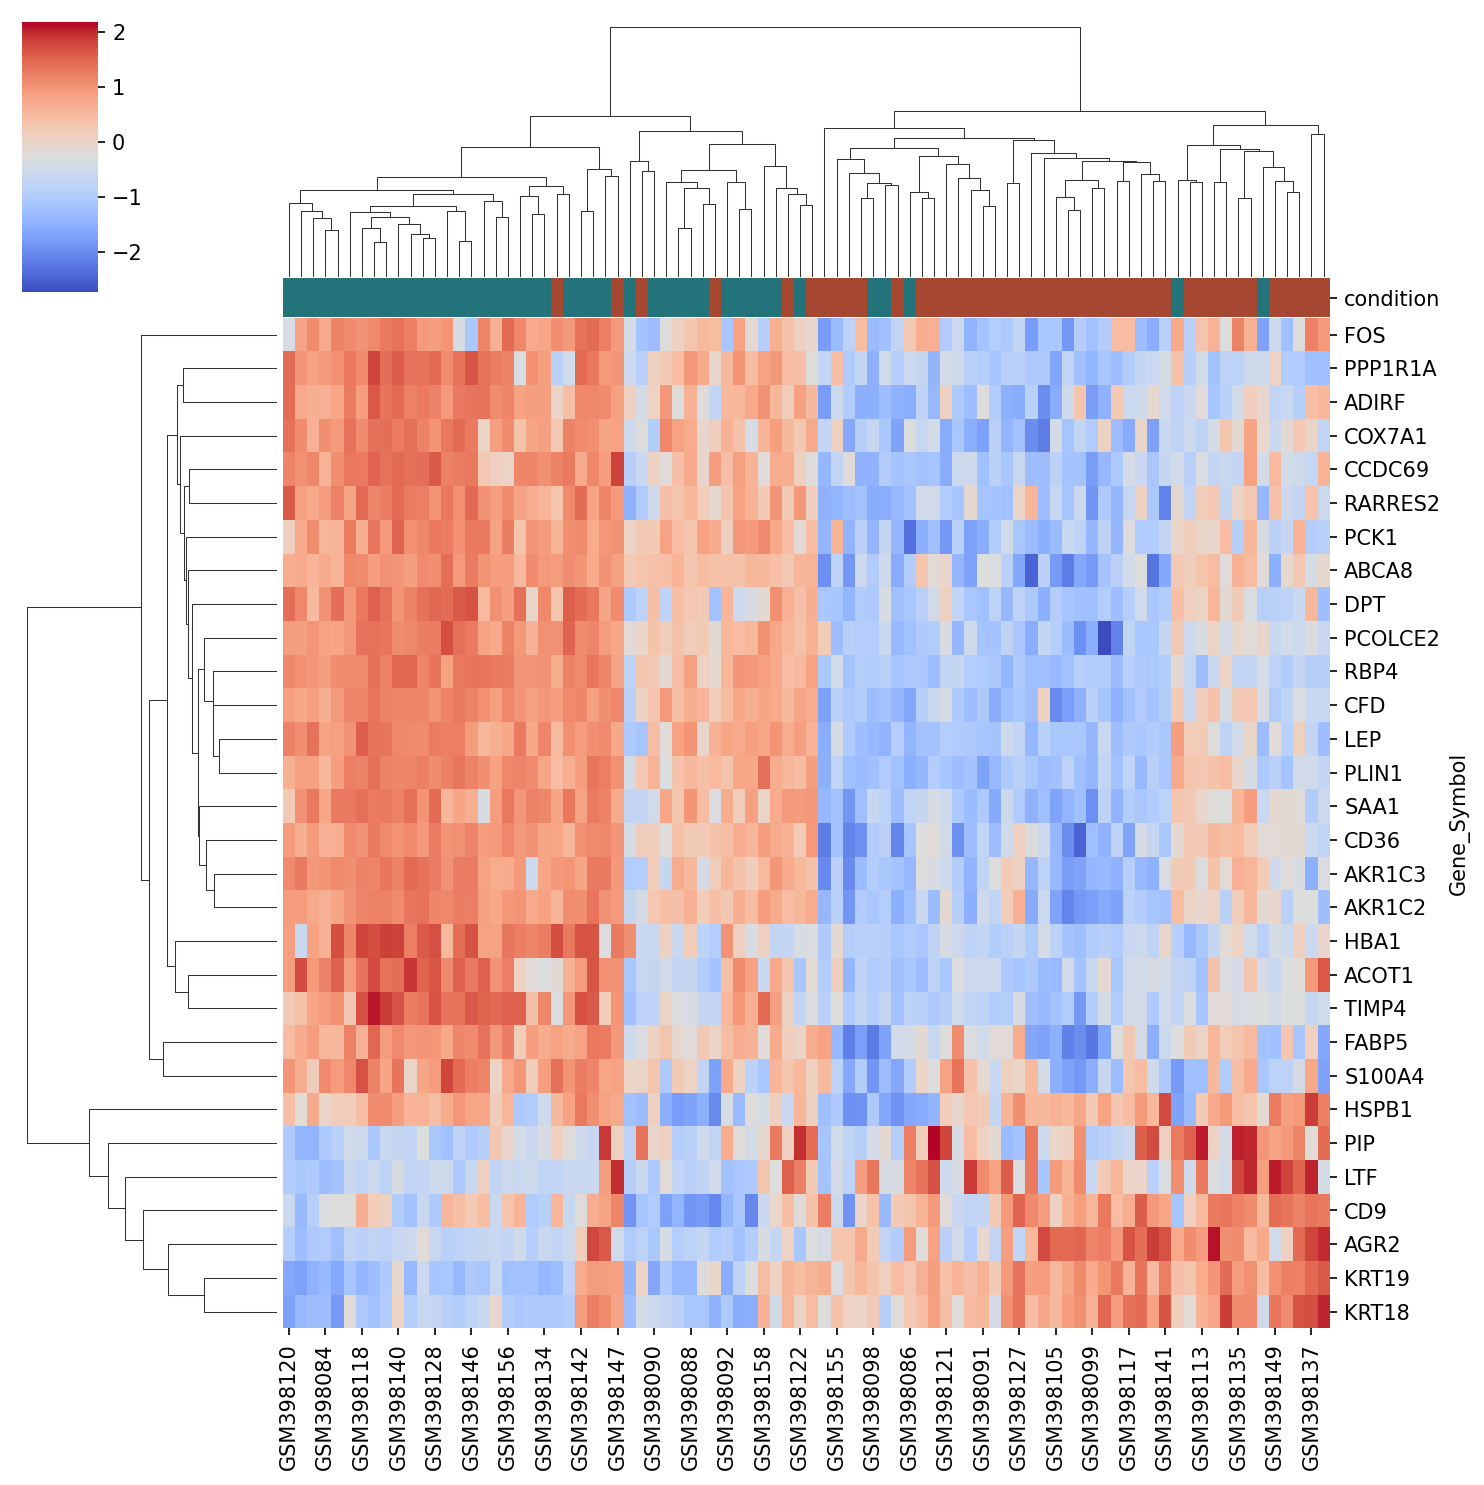

In [25]:
display(Image(filename=str(heatmap_plot(expression, metadata)), width=820))

Genes were selected by overall variance without using tissue labels. Heatmap colours represent within-gene z-scores. Each side bar shows the median of the 43 tumour-minus-normal differences for that gene on the logged scale. KRT19 and AGR2 have large positive paired differences among the displayed genes, while RBP4 and PPP1R1A have large negative differences. Stage 5 will test gene-level differences statistically.

# Stage 5: Differential gene expression
Data: 13,237 genes x 86 samples (log2-scale expression), 43 patients each with one tumour and one matched normal sample.

Method: Paired t-test per gene on log2 expression (tumour vs matched normal), with Benjamini-Hochberg FDR correction. Because the data are normalized log2 expression and not raw counts, this is an exploratory comparison, not count-based RNA-seq DE (DESeq2/edgeR). log2FC is the mean paired difference in log2 values.

Threshold: FDR < 0.05 and |log2FC| >= 1.

Results
2,706 genes have FDR < 0.05; 216 also have |log2FC| >= 1 (60 higher in tumour, 156 lower).
The strongest signals are mostly lower in tumour: G0S2, RBP4, ITIH5, MAOA, LPL, ADIPOQ, CIDEC. Many are adipose or lipid-metabolism genes, and AKR1C1/AKR1C2 are involved in steroid metabolism. This probably reflects normal breast tissue being fat-rich, so part of the signal is tissue composition and not only tumour biology.
DNA-repair / proliferation genes: AURKA (+0.62), TOP2A (+0.80), ERBB2 (+0.47) and PARP1 (+0.25) are significant at FDR < 0.05 but below the |log2FC| >= 1 cutoff. BRCA2 is slightly lower (-0.31). BRCA1, RAD51 and MKI67 are not significant.
What this does not show
These are associations, not causal effects. Results depend on how the data were normalized upstream, and a statistically significant gene with a small fold change may not be biologically large.

In [ ]:
%pip install scipy matplotlib

In [20]:
import pandas as pd, numpy as np
from scipy import stats
import os

# Safely load the cleaned data produced during Stage 3
clean_expr_path = "data/person2/clean_expression.csv"
clean_meta_path = "data/person2/clean_metadata.csv"

# Fallback to local memory variables if physical file is missing during inline compilation
if os.path.exists(clean_expr_path):
    expr = pd.read_csv(clean_expr_path, index_col=0)
else:
    expr = clean_expression

if os.path.exists(clean_meta_path):
    meta = pd.read_csv(clean_meta_path)
else:
    meta = metadata.reset_index()

tum = meta[meta.condition=="Tumor"].set_index("patient_id").sample_id
nor = meta[meta.condition=="Normal"].set_index("patient_id").sample_id
pats = sorted(set(tum.index) & set(nor.index))            # 43 pairs
T = expr[tum.loc[pats].values].values
N = expr[nor.loc[pats].values].values

t, p = stats.ttest_rel(T, N, axis=1)                      # paired test per gene
res = pd.DataFrame({"gene": expr.index, "log2FC": (T-N).mean(1), "t_stat": t, "pvalue": p})

def bh(p):                                                # Benjamini–Hochberg
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    r = np.minimum.accumulate((p[o]*n/np.arange(1, n+1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(r, 1); return out

res["padj"] = bh(res.pvalue.fillna(1).values)
res = res.sort_values("padj")
sig = (res.padj < 0.05) & (res.log2FC.abs() >= 1)
print("Stage 5 Preprocessing Completed!")

Stage 5 Preprocessing Completed!


In [21]:
print(len(pats), "pairs;", len(res), "genes")
print("FDR<0.05:", (res.padj < 0.05).sum(), "| with |log2FC|>=1:", sig.sum(),
      "| up:", (sig & (res.log2FC > 0)).sum(), "| down:", (sig & (res.log2FC < 0)).sum())

43 pairs; 13237 genes
FDR<0.05: 2706 | with |log2FC|>=1: 216 | up: 60 | down: 156


In [22]:
res.to_csv("de_results.csv", index=False)
res.head(15)

,gene,log2FC,t_stat,pvalue,padj
8390,G0S2,-1.507552,-12.992563,2.631584e-16,3.483427e-12
10937,RBP4,-3.540891,-12.365864,1.378033e-15,5.389974e-12
7296,AKAP12,-1.463029,-12.257951,1.841740e-15,5.389974e-12
10872,ITIH5,-1.580850,-12.273996,1.763834e-15,5.389974e-12
11471,PCDH9,-1.766810,-12.220779,2.035950e-15,5.389974e-12
2801,MAOA,-1.890160,-12.043292,3.293873e-15,6.239936e-12
7424,GYG2,-1.831594,-11.996557,3.741220e-15,6.239936e-12
2155,LPL,-1.761588,-11.993630,3.771209e-15,6.239936e-12
5175,ADIPOQ,-1.971309,-11.921716,4.590198e-15,6.751161e-12
6755,PDZD2,-1.534022,-11.870949,5.275430e-15,6.983086e-12


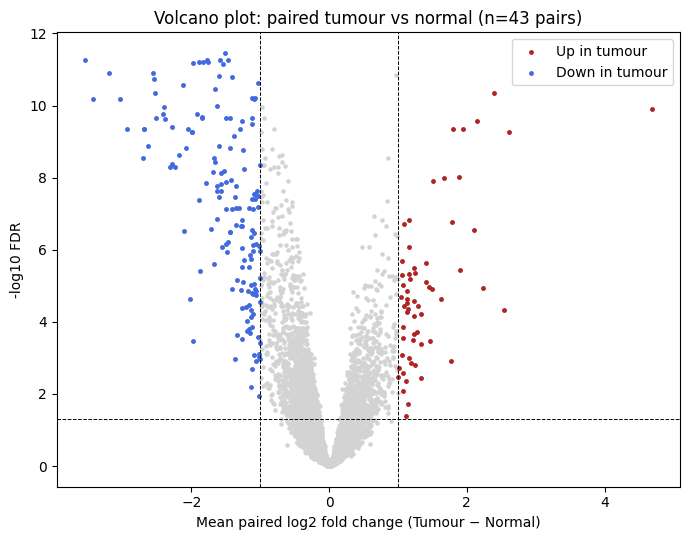

In [23]:
import matplotlib.pyplot as plt

res["nlp"] = -np.log10(res.padj.clip(lower=1e-300))
up = sig & (res.log2FC > 0)
dn = sig & (res.log2FC < 0)

plt.figure(figsize=(7, 5.5))
plt.scatter(res.log2FC, res.nlp, s=5, c="lightgrey")
plt.scatter(res.log2FC[up], res.nlp[up], s=6, c="firebrick", label="Up in tumour")
plt.scatter(res.log2FC[dn], res.nlp[dn], s=6, c="royalblue", label="Down in tumour")
for x in (-1, 1):
    plt.axvline(x, ls="--", c="k", lw=0.7)
plt.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7)
plt.xlabel("Mean paired log2 fold change (Tumour − Normal)")
plt.ylabel("-log10 FDR")
plt.title("Volcano plot: paired tumour vs normal (n=43 pairs)")
plt.legend()
plt.tight_layout()
plt.savefig("volcano.png", dpi=200)
plt.show()

In [24]:
genes = ["BRCA1", "BRCA2", "RAD51", "PARP1", "TOP2A", "AURKA", "MKI67", "ERBB2"]
res[res.gene.isin(genes)][["gene", "log2FC", "pvalue", "padj"]]

,gene,log2FC,pvalue,padj
2574,AURKA,0.623682,0.000035,0.000700
6112,BRCA2,-0.311929,0.000687,0.007142
7416,ERBB2,0.472071,0.000820,0.008144
568,TOP2A,0.802741,0.000941,0.008980
6319,PARP1,0.251702,0.002778,0.019678
3307,RAD51,-0.137634,0.167952,0.322434
7659,MKI67,0.057543,0.355154,0.531466
2916,BRCA1,0.056870,0.713977,0.826417


# Stage 6: Biological Interpretation and pathway Enrichment

# 0. Setup

In [27]:

import sys, subprocess
def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
try:
    import gseapy, gprofiler, networkx, statsmodels
except ImportError:
    _pip("gseapy", "gprofiler-official", "networkx", "statsmodels")

In [28]:
import os, re, json, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
import gseapy as gp

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 80, "display.width", 160)
print("gseapy", gp.__version__, "| pandas", pd.__version__, "| run date", datetime.date.today())


gseapy 1.3.2 | pandas 2.2.3 | run date 2026-11-18


# 1. Configuration

In [29]:
# ---------- input ----------
DE_PATH = "de_results.csv"          # local copy (used first if present)
DE_URL  = "https://raw.githubusercontent.com/NyamburaWanjohi/Bioinformatics_project/main/data/person4/de_results.csv"
                                    # Person 4's committed table (used if no local copy). Falls back to an upload prompt.

# ---------- gene-list rule: MUST match Person 4's declared threshold ----------
FDR_ALPHA  = 0.05                   # adjusted p-value cut-off for 'differentially expressed'
LFC_CUTOFF = 1.0                    # |log2 fold change| cut-off (set to 0.0 to use FDR only)
# Direction convention: positive log2FC must mean HIGHER IN TUMOUR. Confirm with Person 4.
POSITIVE_LFC_MEANS = "higher in tumour"

# ---------- enrichment settings ----------
ORGANISM_ENRICHR = "Human"
LIBRARIES = {                       # short label -> Enrichr library name
    "Reactome": "Reactome_2022",
    "KEGG":     "KEGG_2021_Human",
    "GO_BP":    "GO_Biological_Process_2023",
    "Hallmark": "MSigDB_Hallmark_2020",
}
MIN_SET_SIZE   = 10                 # gene-set size AFTER restricting to the background
MAX_SET_SIZE   = 500
MIN_OVERLAP    = 3                  # a pathway needs at least this many hits to be reported
ENRICH_ALPHA   = 0.05               # BH-adjusted p-value for calling a pathway 'significant'

# ---------- optional STRING / NetworkX add-on ----------
RUN_NETWORK       = True
NETWORK_N_GENES   = 40              # top genes by |log2FC| among significant genes
STRING_MIN_SCORE  = 700             # high confidence

OUT_DIR = "."                       # outputs are written here

In [30]:
if os.path.exists(DE_PATH):
    SRC = DE_PATH
else:
    try:
        pd.read_csv(DE_URL, nrows=2)
        SRC = DE_URL
    except Exception:
        try:
            from google.colab import files
            print("Could not read Person 4's file from GitHub. Upload de_results.csv")
            up = files.upload()
            SRC = DE_PATH = list(up.keys())[0]
        except ImportError:
            raise FileNotFoundError("de_results.csv not found locally or at DE_URL.")

de_raw = pd.read_csv(SRC)
print("Loaded", SRC, "->", de_raw.shape)
display(de_raw.head())
print("\nColumns:", list(de_raw.columns))

Loaded de_results.csv -> (13237, 5)


,gene,log2FC,t_stat,pvalue,padj
0,G0S2,-1.507552,-12.992563,2.631584e-16,3.483427e-12
1,RBP4,-3.540891,-12.365864,1.378033e-15,5.389974e-12
2,AKAP12,-1.463029,-12.257951,1.841740e-15,5.389974e-12
3,ITIH5,-1.580850,-12.273996,1.763834e-15,5.389974e-12
4,PCDH9,-1.766810,-12.220779,2.035950e-15,5.389974e-12



Columns: ['gene', 'log2FC', 't_stat', 'pvalue', 'padj']


In [31]:
def pick(df, candidates, what, required=True):
    low = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    if required:
        raise KeyError(f"No column for {what}. Looked for {candidates}. Columns present: {list(df.columns)}")
    return None

COL_GENE = pick(de_raw, ["gene_id", "gene", "gene_symbol", "symbol", "gene_name", "ensembl_id", "id", "Unnamed: 0"], "gene ID")
COL_LFC  = pick(de_raw, ["log2fc", "log2foldchange", "logfc", "log2_fold_change", "effect", "effect_estimate", "lfc"], "effect estimate (log2 FC)")
COL_P    = pick(de_raw, ["pvalue", "p_value", "pval", "p.value", "p"], "raw p-value")
COL_FDR  = pick(de_raw, ["padj", "fdr", "adj_p", "adj_pval", "adjusted_p", "adj_p_value", "qvalue", "q_value", "adj.p.val"], "adjusted p-value (FDR)")
COL_SYM  = pick(de_raw, ["gene_symbol", "symbol", "gene_name", "hgnc_symbol"], "gene symbol", required=False)
print(f"gene={COL_GENE} | lfc={COL_LFC} | p={COL_P} | fdr={COL_FDR} | symbol={COL_SYM}")

de = de_raw.rename(columns={COL_GENE: "gene_id", COL_LFC: "lfc", COL_P: "p", COL_FDR: "fdr"}).copy()
if COL_SYM and COL_SYM != COL_GENE:
    de = de.rename(columns={COL_SYM: "symbol"})
for c in ["lfc", "p", "fdr"]:
    de[c] = pd.to_numeric(de[c], errors="coerce")

n0 = len(de)
n_nan = int(de[["lfc", "fdr"]].isna().any(axis=1).sum())
de = de.dropna(subset=["lfc", "fdr"])
n_dup = int(de["gene_id"].duplicated().sum())
de = de.sort_values("fdr").drop_duplicates("gene_id", keep="first")
assert (de["fdr"].between(0, 1)).all(), "FDR column has values outside [0, 1]: is it really an adjusted p-value?"
# FDR should never be smaller than the raw p for the same gene (BH only inflates). Catch swapped columns.
if de["p"].notna().any():
    swapped = (de["fdr"] + 1e-12 < de["p"]).mean()
    assert swapped < 0.01, f"{swapped:.1%} of genes have FDR < raw p: columns look swapped."
print(f"Rows in file: {n0} | dropped for missing lfc/FDR: {n_nan} | duplicate gene IDs removed (kept best FDR): {n_dup} | kept: {len(de)}")

gene=gene | lfc=log2FC | p=pvalue | fdr=padj | symbol=None
Rows in file: 13237 | dropped for missing lfc/FDR: 0 | duplicate gene IDs removed (kept best FDR): 0 | kept: 13237


# 3. Gene identifiers → HGNC symbols
Enrichment libraries use gene symbols. If Person 4's table already has a symbol column it is used as is; if the IDs are Ensembl (ENSG…), they are converted with g:Convert and the number lost is reported.

In [32]:
def looks_ensembl(s):
    return s.astype(str).str.match(r"^ENSG\d+").mean() > 0.8

if "symbol" in de.columns:
    de["symbol"] = de["symbol"].astype(str)
    id_source = "symbol column supplied in de_results.csv"
elif looks_ensembl(de["gene_id"]):
    from gprofiler import GProfiler
    de["ensg"] = de["gene_id"].astype(str).str.replace(r"\.\d+$", "", regex=True)   # strip version suffix
    conv = GProfiler(return_dataframe=True).convert(organism="hsapiens", query=de["ensg"].unique().tolist())
    mapping = (conv[conv["name"].astype(str).str.lower() != "none"]
               .drop_duplicates("incoming").set_index("incoming")["name"])
    de["symbol"] = de["ensg"].map(mapping)
    id_source = "Ensembl IDs converted with g:Convert"
else:
    de["symbol"] = de["gene_id"].astype(str)
    id_source = "gene_id column treated as HGNC symbols"

n_before = len(de)
de = de[de["symbol"].notna() & ~de["symbol"].isin(["nan", "None", ""])].copy()
# several IDs can map to one symbol: keep the most significant
n_multi = int(de["symbol"].duplicated().sum())
de = de.sort_values("fdr").drop_duplicates("symbol", keep="first")
print(f"ID handling: {id_source}")
print(f"Genes with a usable symbol: {len(de)} of {n_before} ({n_before-len(de)} unmapped) | symbol collisions collapsed: {n_multi}")
display(de[["gene_id", "symbol", "lfc", "p", "fdr"]].head())


ID handling: gene_id column treated as HGNC symbols
Genes with a usable symbol: 13237 of 13237 (0 unmapped) | symbol collisions collapsed: 0


,gene_id,symbol,lfc,p,fdr
0,G0S2,G0S2,-1.507552,2.631584e-16,3.483427e-12
1,RBP4,RBP4,-3.540891,1.378033e-15,5.389974e-12
2,AKAP12,AKAP12,-1.463029,1.841740e-15,5.389974e-12
3,ITIH5,ITIH5,-1.580850,1.763834e-15,5.389974e-12
4,PCDH9,PCDH9,-1.766810,2.035950e-15,5.389974e-12


# Define the gene lists and the background universe
**Significant genes**: FDR < FDR_ALPHA and |log2FC| ≥ LFC_CUTOFF, split into up in tumour and down in tumour.

**Background universe:** every gene that was actually tested in the DE analysis (after Person 2's filtering). Using the whole genome instead would inflate enrichment because unexpressed genes could never have been detected as significant.

In [34]:
BACKGROUND = sorted(de["symbol"].unique())
sig  = de[(de["fdr"] < FDR_ALPHA) & (de["lfc"].abs() >= LFC_CUTOFF)]
UP   = sorted(sig.loc[sig["lfc"] > 0, "symbol"])
DOWN = sorted(sig.loc[sig["lfc"] < 0, "symbol"])

gene_lists = pd.DataFrame({
    "set": ["background (all tested)", "significant total", f"up ({POSITIVE_LFC_MEANS})", f"down (lower in tumour)"],
    "n_genes": [len(BACKGROUND), len(sig), len(UP), len(DOWN)],
})
display(gene_lists)
print(f"Rule used: FDR < {FDR_ALPHA} and |log2FC| >= {LFC_CUTOFF}")
if len(UP) + len(DOWN) == 0:
    print("WARNING: no significant genes under this rule. Enrichment cannot be run; report this honestly in Stage 6.")
for name, g in [("UP", UP), ("DOWN", DOWN)]:
    if 0 < len(g) < 15:
        print(f"WARNING: {name} list has only {len(g)} genes: enrichment will have very little power.")
    if len(g) > 0.4 * len(BACKGROUND):
        print(f"WARNING: {name} list is {len(g)/len(BACKGROUND):.0%} of the background: results will be hard to interpret. Consider a stricter cut-off and say so.")

,set,n_genes
0,background (all tested),13237
1,significant total,216
2,up (higher in tumour),60
3,down (lower in tumour),156


Rule used: FDR < 0.05 and |log2FC| >= 1.0


# 5. Enrichment function (over-representation analysis)
For each gene set with K genes inside a universe of N genes, and a hit list of n genes of which k fall in the set, the p-value is the upper tail of the hypergeometric distribution, P(X ≥ k). Gene sets are first restricted to the background, and the universe N is the set of background genes that have at least one annotation in that library. P-values are corrected with Benjamini–Hochberg across all gene sets tested in that library for that list.

In [35]:
def ora(hits, background, gene_sets, min_size=MIN_SET_SIZE, max_size=MAX_SET_SIZE, min_overlap=MIN_OVERLAP):
    # One-sided hypergeometric over-representation test with BH correction.
    bg = set(background)
    hits = set(hits) & bg
    restricted = {t: set(g) & bg for t, g in gene_sets.items()}
    universe = set().union(*restricted.values()) if restricted else set()
    hits = hits & universe                       # hits with no annotation cannot be tested
    N, n = len(universe), len(hits)
    rows = []
    for term, members in restricted.items():
        K = len(members)
        if not (min_size <= K <= max_size):
            continue
        overlap = hits & members
        k = len(overlap)
        p = hypergeom.sf(k - 1, N, K, n) if n > 0 else 1.0
        fold = (k / n) / (K / N) if n > 0 and K > 0 else np.nan
        rows.append((term, K, k, n, N, fold, p, ";".join(sorted(overlap))))
    out = pd.DataFrame(rows, columns=["pathway", "set_size", "overlap", "list_size", "background_size",
                                      "fold_enrichment", "p_value", "overlap_genes"])
    if len(out):
        out["adj_p_value"] = multipletests(out["p_value"].values, method="fdr_bh")[1]
        out["n_sets_tested"] = len(out)
        out = out[out["overlap"] >= min_overlap].sort_values(["adj_p_value", "p_value"]).reset_index(drop=True)
    return out

# ---- unit self-test on a toy example (this is a code check, NOT a result) ----
_bg = [f"G{i}" for i in range(100)]
_sets = {"A": {f"G{i}" for i in range(0, 20)}, "B": {f"G{i}" for i in range(50, 70)}, "C": {f"G{i}" for i in range(80, 95)}}
_hits = [f"G{i}" for i in range(0, 12)]
_t = ora(_hits, _bg, _sets, min_size=5, max_size=50, min_overlap=1).set_index("pathway")
_N = len(set().union(*_sets.values()))          # universe = genes with any annotation (55 here)
_exp = hypergeom.sf(12 - 1, _N, 20, 12)
assert abs(_t.loc["A", "p_value"] - _exp) < 1e-12, "hypergeometric p-value does not match scipy"
assert _t.loc["A", "adj_p_value"] >= _t.loc["A", "p_value"], "BH adjustment must not lower p-values"
print("ORA self-test passed (toy data only).")

ORA self-test passed (toy data only).


# 6. Load gene-set libraries and record exactly what was used

In [47]:
available = set(gp.get_library_name(organism=ORGANISM_ENRICHR))
missing = {k: v for k, v in LIBRARIES.items() if v not in available}
if missing:
    print("Library names not found in Enrichr (edit LIBRARIES in section 1):", missing)
    # try the newest library that shares the same stem
    for label, name in list(missing.items()):
        stem = re.sub(r"_\d{4}.*$", "", name)
        cand = sorted(a for a in available if a.startswith(stem))
        if cand:
            LIBRARIES[label] = cand[-1]
            print(f"  -> using {cand[-1]} for {label}")
        else:
            LIBRARIES.pop(label)
GENE_SETS = {label: gp.get_library(name, organism=ORGANISM_ENRICHR) for label, name in LIBRARIES.items()}
bg_set = set(BACKGROUND)
for label, gs in GENE_SETS.items():
    annotated = bg_set & set().union(*map(set, gs.values()))
    pct = 100 * len(annotated) / len(bg_set) if len(bg_set) > 0 else 0.0
    print(f"{label:9s} {LIBRARIES[label]:32s} {len(gs):5d} gene sets | background genes annotated: {len(annotated)}/{len(bg_set)} ({pct:.1f}%)")

Reactome  Reactome_2022                     1816 gene sets | background genes annotated: 7594/13237 (57.4%)
KEGG      KEGG_2021_Human                    320 gene sets | background genes annotated: 5867/13237 (44.3%)
GO_BP     GO_Biological_Process_2023        5406 gene sets | background genes annotated: 10010/13237 (75.6%)
Hallmark  MSigDB_Hallmark_2020                50 gene sets | background genes annotated: 4011/13237 (30.3%)


# 7. Run the enrichment

In [42]:
results = []
for direction, hits in [("up_in_tumour", UP), ("down_in_tumour", DOWN)]:
    if len(hits) == 0:
        continue
    for label, gs in GENE_SETS.items():
        r = ora(hits, BACKGROUND, gs)
        if len(r):
            r.insert(0, "library", label)
            r.insert(0, "direction", direction)
            results.append(r)

pathway_results = (pd.concat(results, ignore_index=True) if results else
                   pd.DataFrame(columns=["direction", "library", "pathway", "set_size", "overlap", "list_size",
                                         "background_size", "fold_enrichment", "p_value", "overlap_genes",
                                         "adj_p_value", "n_sets_tested"]))
pathway_results["significant"] = pathway_results["adj_p_value"] < ENRICH_ALPHA
pathway_results.to_csv(os.path.join(OUT_DIR, "pathway_results.csv"), index=False)

print(f"Pathways reported (overlap >= {MIN_OVERLAP}): {len(pathway_results)}")
summary = (pathway_results.groupby(["direction", "library"])["significant"].agg(["size", "sum"])
           .rename(columns={"size": "tested_with_overlap", "sum": f"significant_BH<{ENRICH_ALPHA}"}))
display(summary)

Pathways reported (overlap >= 3): 499


tested_with_overlap  significant_BH<0.05
direction      library                                           
down_in_tumour GO_BP                     238                   40
               Hallmark                   24                    5
               KEGG                       89                    3
               Reactome                   88                    5
up_in_tumour   GO_BP                      36                    0
               Hallmark                    8                    3
               KEGG                        2                    0
               Reactome                   14                    0

# 8. Pathway charts

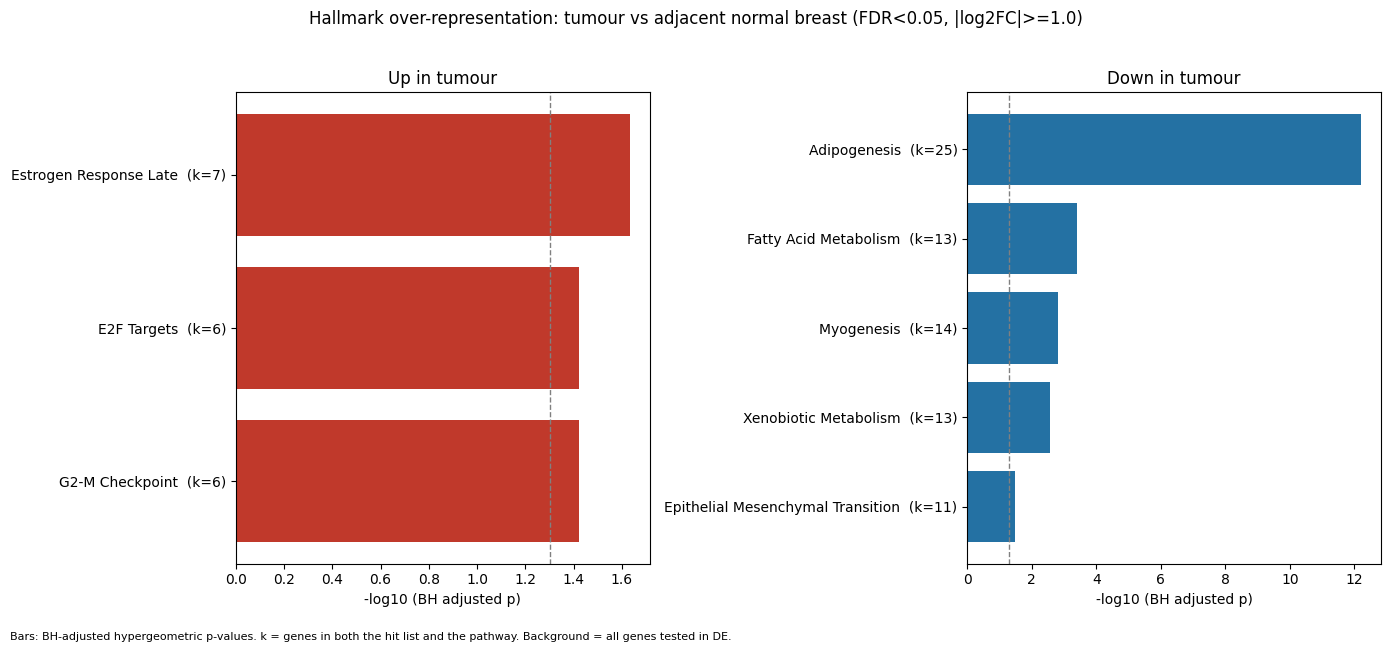

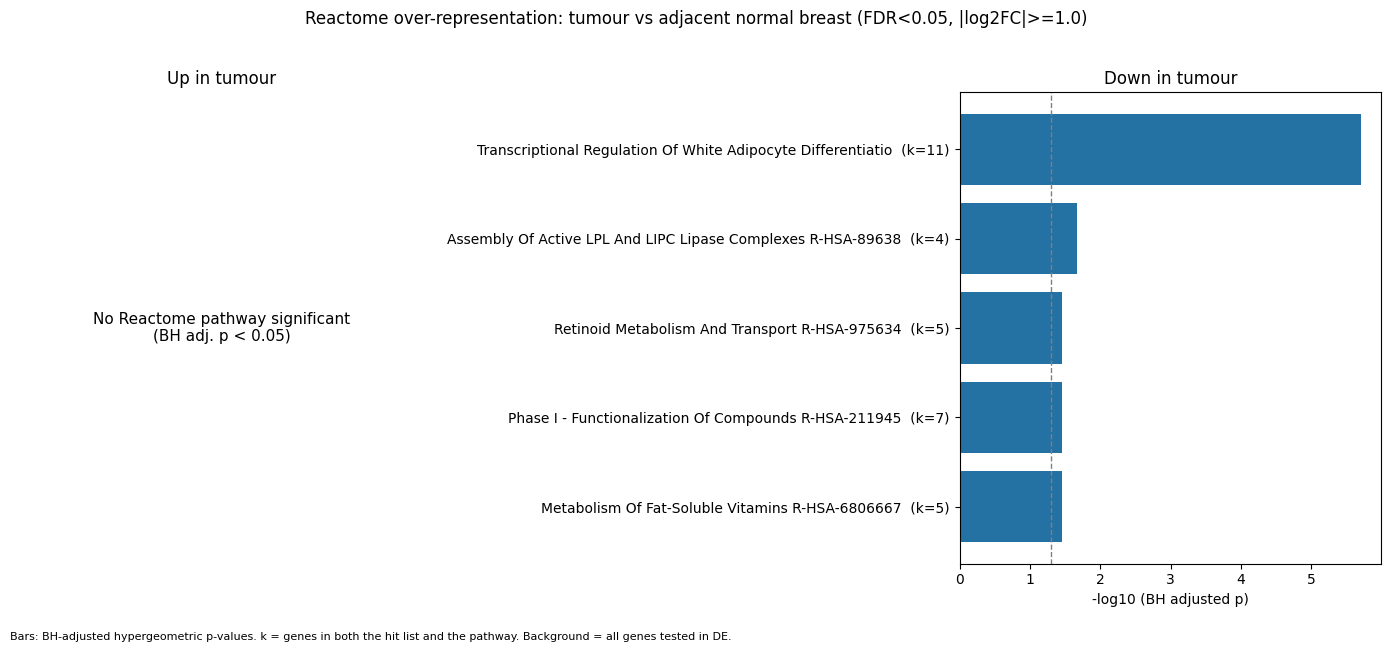

In [48]:
def plot_top(library, top_n=10, fname=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, max(3.5, 0.45 * top_n + 1.5)), sharex=False)
    colors = {"up_in_tumour": "#C0392B", "down_in_tumour": "#2471A3"}
    titles = {"up_in_tumour": "Up in tumour", "down_in_tumour": "Down in tumour"}
    any_hit = False
    for ax, direction in zip(axes, ["up_in_tumour", "down_in_tumour"]):
        d = pathway_results[(pathway_results["library"] == library) & (pathway_results["direction"] == direction)
                            & pathway_results["significant" ]].sort_values("adj_p_value").head(top_n)
        if d.empty:
            ax.text(0.5, 0.5, f"No {library} pathway significant\n(BH adj. p < {ENRICH_ALPHA})",
                    ha="center", va="center", transform=ax.transAxes, fontsize=11)
            ax.set_axis_off(); ax.set_title(titles[direction]); continue
        any_hit = True
        d = d.iloc[::-1]
        labels = [re.sub(r"\s*\n", "", t)[:60] + f"  (k={k})" for t, k in zip(d["pathway"], d["overlap"])]
        ax.barh(labels, -np.log10(d["adj_p_value"].clip(lower=1e-300)), color=colors[direction])
        ax.axvline(-np.log10(ENRICH_ALPHA), ls="--", c="grey", lw=1)
        ax.set_xlabel("-log10 (BH adjusted p)"); ax.set_title(titles[direction])
    fig.suptitle(f"{library} over-representation: tumour vs adjacent normal breast "
                 f"(FDR<{FDR_ALPHA}, |log2FC|>={LFC_CUTOFF})", y=1.02)
    fig.text(0.01, -0.03, "Bars: BH-adjusted hypergeometric p-values. k = genes in both the hit list and the pathway. "
             "Background = all genes tested in DE.", fontsize=8, ha="left")
    fig.tight_layout()
    fig.savefig(fname or os.path.join(OUT_DIR, f"pathway_chart_{library}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    return any_hit

for lib in [l for l in ["Hallmark", "Reactome"] if l in GENE_SETS]:
    plot_top(lib)

# 9. How fragile is the result? (threshold sensitivity)

In [49]:
SENS_LIB = "Hallmark"
print("Sensitivity library:", SENS_LIB)

def hallmark_hits(fdr_a, lfc_c):
    s = de[(de["fdr"] < fdr_a) & (de["lfc"].abs() >= lfc_c)]
    return sorted(s.loc[s["lfc"] > 0, "symbol"]), sorted(s.loc[s["lfc"] < 0, "symbol"])

sens_rows = []
if SENS_LIB:
    for fa, lc in [(FDR_ALPHA, LFC_CUTOFF), (FDR_ALPHA, 0.0), (FDR_ALPHA, 1.5), (0.01, 1.0)]:
        u, d_ = hallmark_hits(fa, lc)
        for dirn, hits in [("up_in_tumour", u), ("down_in_tumour", d_)]:
            r = ora(hits, BACKGROUND, GENE_SETS[SENS_LIB]) if len(hits) else pd.DataFrame()
            sig_terms = r.loc[r["adj_p_value"] < ENRICH_ALPHA, "pathway"].tolist() if len(r) else []
            sens_rows.append({"FDR<": fa, "|log2FC|>=": lc, "direction": dirn, "n_genes": len(hits),
                              "n_sig_sets": len(sig_terms), "top3": "; ".join(sig_terms[:3])})
sens = pd.DataFrame(sens_rows)
display(sens)
sens.to_csv(os.path.join(OUT_DIR, "pathway_sensitivity.csv"), index=False)

Sensitivity library: Hallmark


,FDR<,|log2FC|>=,direction,n_genes,n_sig_sets,top3
0,0.05,1.0,up_in_tumour,60,3,Estrogen Response Late; E2F Targets; G2-M Checkpoint
1,0.05,1.0,down_in_tumour,156,5,Adipogenesis; Fatty Acid Metabolism; Myogenesis
2,0.05,0.0,up_in_tumour,777,6,Myc Targets V1; G2-M Checkpoint; E2F Targets
3,0.05,0.0,down_in_tumour,1929,12,Adipogenesis; Hypoxia; Fatty Acid Metabolism
4,0.05,1.5,up_in_tumour,16,1,Estrogen Response Late
5,0.05,1.5,down_in_tumour,62,2,Adipogenesis; Fatty Acid Metabolism
6,0.01,1.0,up_in_tumour,58,3,Estrogen Response Late; E2F Targets; G2-M Checkpoint
7,0.01,1.0,down_in_tumour,155,5,Adipogenesis; Fatty Acid Metabolism; Myogenesis


# 10. Optional add-on: STRING interaction network

STRING v12.5: 40 query genes, 25 connected, 39 edges (score >= 700)


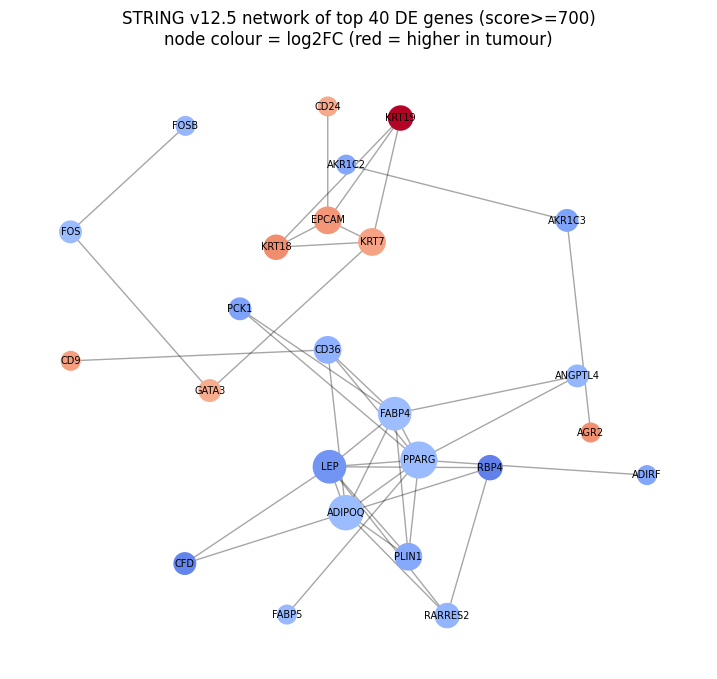

Highest-degree genes: [('PPARG', 9), ('ADIPOQ', 8), ('LEP', 7), ('FABP4', 7), ('PLIN1', 4)]
{
  "run_date": "2026-11-18",
  "input_file": "de_results.csv",
  "n_genes_in_file": 13237,
  "n_genes_tested_used_as_background": 13237,
  "id_handling": "gene_id column treated as HGNC symbols",
  "gene_list_rule": {
    "fdr_alpha": 0.05,
    "abs_log2fc_min": 1.0,
    "positive_lfc_means": "higher in tumour"
  },
  "n_up": 60,
  "n_down": 156,
  "test": "one-sided hypergeometric (ORA), BH FDR within each list x library",
  "set_size_filter": [
    10,
    500
  ],
  "min_overlap": 3,
  "enrichment_alpha": 0.05,
  "libraries": {
    "Reactome": "Reactome_2022",
    "KEGG": "KEGG_2021_Human",
    "GO_BP": "GO_Biological_Process_2023",
    "Hallmark": "MSigDB_Hallmark_2020"
  },
  "gseapy_version": "1.3.2",
  "seed": 42,
  "network": {
    "ran": true,
    "string_version": "12.5",
    "n_query": 40,
    "n_connected": 25,
    "n_edges": 39,
    "min_score": 700
  }
}


In [53]:
network_info = {"ran": False}
if RUN_NETWORK and len(sig) > 0:
    try:
        import requests, networkx as nx
        net_genes = sig.reindex(sig["lfc"].abs().sort_values(ascending=False).index).head(NETWORK_N_GENES)
        ids = net_genes["symbol"].tolist()
        base = "https://string-db.org/api/json"
        string_version = requests.get(f"{base}/version", timeout=30).json()[0]["string_version"]
        resp = requests.post(f"{base}/network", timeout=60, data={
            "identifiers": "\r".join(ids), "species": 9606, "required_score": STRING_MIN_SCORE,
            "caller_identity": "group10_bioinformatics_project"})
        resp.raise_for_status()
        edges = pd.DataFrame(resp.json())
        G = nx.Graph()
        G.add_nodes_from(ids)
        if len(edges):
            for a, b, s in edges[["preferredName_A", "preferredName_B", "score"]].itertuples(index=False):
                G.add_edge(a, b, weight=float(s))
        lfc_map = net_genes.set_index("symbol")["lfc"]
        connected = [n for n in G if G.degree(n) > 0]
        H = G.subgraph(connected).copy()
        print(f"STRING v{string_version}: {len(ids)} query genes, {H.number_of_nodes()} connected, {H.number_of_edges()} edges (score >= {STRING_MIN_SCORE})")
        if H.number_of_edges() > 0:
            fig, ax = plt.subplots(figsize=(9, 8))
            pos = nx.spring_layout(H, seed=SEED, k=0.9)
            nx.draw_networkx_edges(H, pos, alpha=0.35, ax=ax)
            nx.draw_networkx_nodes(H, pos, node_size=[120 + 60 * H.degree(n) for n in H],
                                   node_color=[lfc_map.get(n, 0) for n in H], cmap="coolwarm",
                                   vmin=-lfc_map.abs().max(), vmax=lfc_map.abs().max(), ax=ax)
            nx.draw_networkx_labels(H, pos, font_size=7, ax=ax)
            ax.set_title(f"STRING v{string_version} network of top {NETWORK_N_GENES} DE genes (score>={STRING_MIN_SCORE})\n"
                         "node colour = log2FC (red = higher in tumour)")
            ax.set_axis_off()
            fig.savefig(os.path.join(OUT_DIR, "interaction_network.png"), dpi=200, bbox_inches="tight")
            plt.show()
            hubs = sorted(H.degree, key=lambda x: -x[1])[:5]
            print("Highest-degree genes:", hubs)
        network_info = {"ran": True, "string_version": string_version, "n_query": len(ids),
                        "n_connected": H.number_of_nodes(), "n_edges": H.number_of_edges(), "min_score": STRING_MIN_SCORE}
    except Exception as e:
        print("Network step skipped (optional):", type(e).__name__, str(e)[:200])
        network_info = {"ran": False, "error": str(e)[:200]}
else:
    print("Network add-on switched off or no significant genes.")

# 11. Provenance log
# Everything another person needs to reproduce or audit this section.

run_log = {
    "run_date": str(datetime.date.today()),
    "input_file": str(SRC), "n_genes_in_file": int(n0), "n_genes_tested_used_as_background": len(BACKGROUND),
    "id_handling": id_source,
    "gene_list_rule": {"fdr_alpha": FDR_ALPHA, "abs_log2fc_min": LFC_CUTOFF, "positive_lfc_means": POSITIVE_LFC_MEANS},
    "n_up": len(UP), "n_down": len(DOWN),
    "test": "one-sided hypergeometric (ORA), BH FDR within each list x library",
    "set_size_filter": [MIN_SET_SIZE, MAX_SET_SIZE], "min_overlap": MIN_OVERLAP, "enrichment_alpha": ENRICH_ALPHA,
    "libraries": LIBRARIES, "gseapy_version": gp.__version__, "seed": SEED,
    "network": network_info,
}
with open(os.path.join(OUT_DIR, "pathway_run_log.json"), "w") as f:
    json.dump(run_log, f, indent=2)
print(json.dumps(run_log, indent=2))

# 12. Biological interpretation (write this after the tables and charts above have run)
Instructions for the author. Replace each … with what your run produced. Delete any prompt that does not apply. Do not describe a pathway as enriched unless it is in the significant table above, and quote its adjusted p-value and overlap. Never copy text from expectations below as if it were a finding.

**1. What the enrichment shows.** Under the rule FDR < … and |log2FC| ≥ … , the list contained … up-regulated and … down-regulated genes against a background of … tested genes. Among up-regulated genes, … pathways were significant (BH < 0.05); the strongest were … (adj. p = …, k = …/…). Among down-regulated genes, … pathways were significant; the strongest were … (If none: "No pathway passed BH correction for this list; the enrichment analysis is inconclusive for this direction.")

**2. Link back to the research question.** The oncogenic signalling gene sets in Hallmark that were significant were … (e.g. cell-cycle, proliferation, PI3K/AKT/mTOR, p53, estrogen-response sets, if present). This supports / does not support the idea that the tumour-vs-normal gene differences map onto … signalling.

**3. Compare with published biology.** Breast tumours are widely reported to show higher proliferation and cell-cycle programmes (e.g. E2F targets, G2-M checkpoint) and lower adipose-related programmes (adipogenesis, fatty-acid metabolism), partly because normal breast tissue is fat-rich. These are hypotheses to check against your own tables and to cite properly, not results. My results agree / disagree on … because …

**4. Robustness.** From the sensitivity table **bold text**: … pathways stayed significant under all four cut-offs; … appeared only under … .

**5. Network (if run)** . STRING network of the top … genes had … edges; the most connected genes were … . This is consistent with / adds to the pathway result by … ; it does not show regulation.

**6. What this does not show.**

Enrichment is association, not causation: a pathway being over-represented does not show it drives the cancer.
ORA depends on the significance cut-off and on which genes were tested (background).
Tumour tissue is a mixture of cell types; differences in cell composition (tumour vs stroma/fat/immune) can produce pathway signals unrelated to cancer-cell signalling.
If the data are not patient-matched, "adjacent normal" differences may include between-patient variation. (Check Person 1's dataset_manifest.md for pairing status.)
If Person 4's comparison was on normalized, not raw counts, the gene list is exploratory and so is this enrichment.
Enrichr libraries are versioned snapshots (see pathway_run_log.json).
7.** One-line takeaway for Stage 8 (Conclusions): **…

# Stage 7: Machine learning classification and baseline evaluation

In [51]:
## Stage 7: Machine learning classification and baseline evaluation (Person 6)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, warnings
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, accuracy_score, roc_auc_score)
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)

In [52]:
import os, shutil
from google.colab import files
os.makedirs("data/person2", exist_ok=True)
print("Select ONLY metadata.csv:")
up = files.upload()
for fn in up.keys():
    shutil.move(fn, "data/person2/clean_metadata.csv")
print(os.listdir("data/person2"))

Select ONLY metadata.csv:


Saving metadata.csv to metadata.csv
['sample_qc.png', 'clean_expression.csv', 'qc_changes.csv', 'gene_row_audit.csv', 'clean_metadata.csv', 'sample_qc.csv', 'heatmap_plot.png', 'distribution_plot.png', 'pca_plot.png', 'qc_before_after.csv']


In [54]:
import shutil
os.makedirs("data/person2", exist_ok=True)
CLEAN_EXPR = "data/person2/clean_expression.csv"
CLEAN_META = "data/person2/clean_metadata.csv"

# If the files are not here yet, ask for them (select BOTH in one go)
if not (os.path.exists(CLEAN_EXPR) and os.path.exists(CLEAN_META)):
    from google.colab import files
    print("Click 'Choose Files' and select BOTH clean_expression.csv and clean_metadata.csv:")
    up = files.upload()
    for fn in up.keys():
        low = fn.lower()
        if "metadata" in low:
            shutil.move(fn, CLEAN_META)
        elif "expression" in low:
            shutil.move(fn, CLEAN_EXPR)

expr = pd.read_csv(CLEAN_EXPR, index_col=0)   # genes x samples (Person 2's file)
meta = pd.read_csv(CLEAN_META, index_col=0).rename_axis("sample_id").reset_index()   # first column = sample ID

# make rows = samples, columns = genes
if meta["sample_id"].isin(expr.columns).mean() > 0.5:
    expr = expr.T
expr.index = expr.index.astype(str)
meta["sample_id"] = meta["sample_id"].astype(str)

# align by sample_id (never rely on row order)
meta = meta.set_index("sample_id").loc[expr.index.intersection(meta["sample_id"])]
expr = expr.loc[meta.index]
X = expr.apply(pd.to_numeric, errors="coerce")

# safety check: Person 2 already made gene symbols unique and applied log2(x+1)
assert X.columns.is_unique, "Duplicate gene symbols found - this does not look like the cleaned file"
if X.max().max() > 100:
    raise ValueError("Values look un-logged; check you uploaded clean_expression.csv, not the raw matrix.")

y = meta["label"].astype(int).values
groups = meta["patient_id"].values
print("X (samples x genes):", X.shape, "| missing values:", int(X.isna().sum().sum()))
print("Patients:", len(set(groups)), "| samples per patient:", pd.Series(groups).value_counts().unique())

X (samples x genes): (86, 13237) | missing values: 0
Patients: 43 | samples per patient: [2]


In [55]:
bal = pd.Series(y).map({0:"Normal",1:"Tumour"}).value_counts().rename("n_samples").to_frame()
bal["fraction"] = (bal["n_samples"]/bal["n_samples"].sum()).round(3)
display(bal)

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
assert set(groups[tr]).isdisjoint(set(groups[te])), "patient leakage!"
print(f"Train: {len(tr)} samples ({len(set(groups[tr]))} patients) | Test: {len(te)} samples ({len(set(groups[te]))} patients)")
print("Test class counts:", {int(k): int(v) for k, v in zip(*np.unique(y_te, return_counts=True))})

,n_samples,fraction
Normal,43,0.5
Tumour,43,0.5


Train: 64 samples (32 patients) | Test: 22 samples (11 patients)
Test class counts: {0: 11, 1: 11}


In [56]:
K = 200  # genes kept by univariate F-test; fixed in advance
def prep():
    return [("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(f_classif, k=min(K, X.shape[1])))]

models = {
    "Dummy baseline": Pipeline([("clf", DummyClassifier(strategy="stratified", random_state=SEED))]),
    "Logistic regression (primary)": Pipeline(prep() + [("clf", LogisticRegression(C=0.1, max_iter=5000, random_state=SEED))]),
    "SVM (linear)": Pipeline(prep() + [("clf", SVC(kernel="linear", C=0.1, probability=True, random_state=SEED))]),
    "Random forest": Pipeline(prep() + [("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))]),
}
for m in models.values():
    m.fit(X_tr, y_tr)

,model,accuracy,precision,recall,f1,roc_auc
0,Dummy baseline,0.409,0.417,0.455,0.435,0.409
1,Logistic regression (primary),0.818,0.818,0.818,0.818,0.901
2,SVM (linear),0.818,0.818,0.818,0.818,0.884
3,Random forest,0.818,0.818,0.818,0.818,0.868


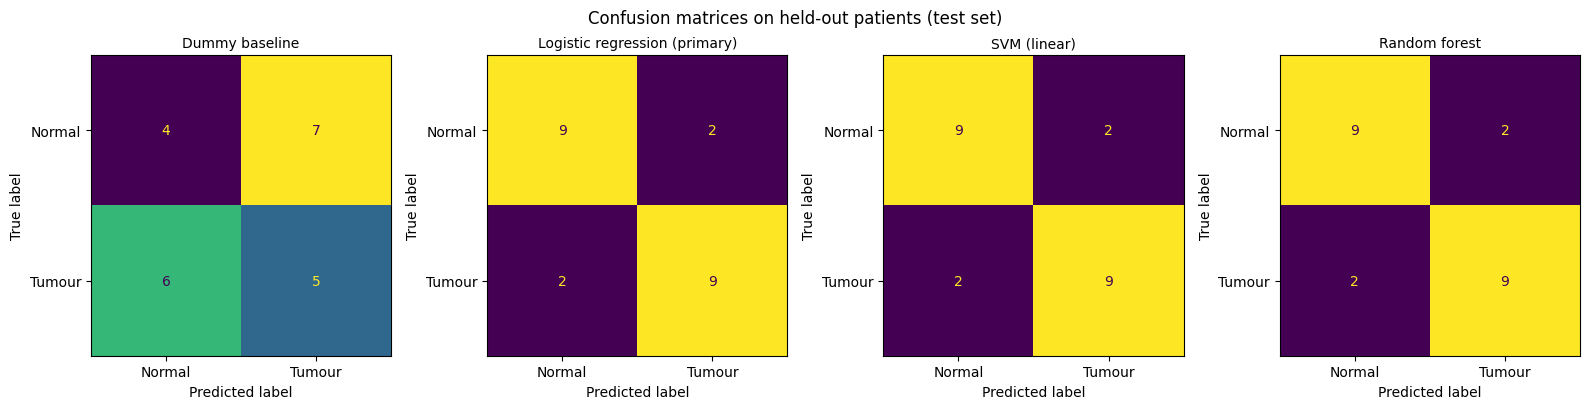

In [57]:
rows, preds = [], {}
for name, est in models.items():
    pred = est.predict(X_te); preds[name] = pred
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_te, pred),
                 "precision": precision_score(y_te, pred, zero_division=0),
                 "recall": recall_score(y_te, pred, zero_division=0),
                 "f1": f1_score(y_te, pred, zero_division=0),
                 "roc_auc": roc_auc_score(y_te, est.predict_proba(X_te)[:, 1])})
metrics = pd.DataFrame(rows).round(3)
metrics.to_csv("outputs/model_metrics.csv", index=False)
display(metrics)

fig, axes = plt.subplots(1, len(models), figsize=(4*len(models), 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0,1]),
                           display_labels=["Normal","Tumour"]).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices on held-out patients (test set)")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix.png", dpi=200); plt.show()

,model,accuracy,f1,roc_auc
0,Dummy baseline,0.350 ± 0.020,0.350 ± 0.020,0.350 ± 0.020
1,Logistic regression (primary),0.872 ± 0.041,0.871 ± 0.039,0.976 ± 0.017
2,SVM (linear),0.863 ± 0.054,0.860 ± 0.050,0.951 ± 0.030
3,Random forest,0.874 ± 0.039,0.871 ± 0.041,0.977 ± 0.024


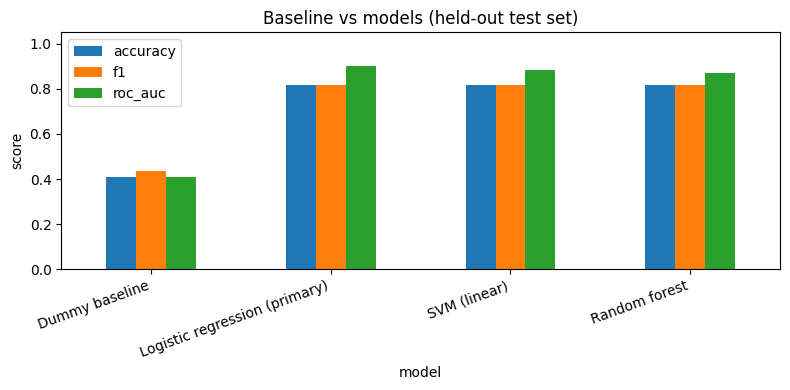

In [58]:
cv = GroupKFold(n_splits=5)
scoring = {"accuracy":"accuracy","f1":"f1","roc_auc":"roc_auc"}
rows = []
for name, est in models.items():
    res = cross_validate(est, X, y, groups=groups, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        v = res[f"test_{m}"]; row[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    rows.append(row)
cv_table = pd.DataFrame(rows)
cv_table.to_csv("outputs/model_metrics_cv.csv", index=False)
display(cv_table)

fig, ax = plt.subplots(figsize=(8,4))
metrics.set_index("model")[["accuracy","f1","roc_auc"]].plot(kind="bar", ax=ax)
ax.set_ylim(0,1.05); ax.set_ylabel("score"); ax.set_title("Baseline vs models (held-out test set)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig("outputs/baseline_vs_model.png", dpi=200); plt.show()

In [59]:
import shutil
shutil.make_archive("stage7_outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("stage7_outputs.zip")
except Exception as e:
    print("Not in Colab, outputs are in the 'outputs' folder:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Leakage-prevention note
- The split is by `patient_id`, so a patient's tumour and matched normal sample are never separated across train and test.
- Imputation, scaling and gene selection (top-200 by F-test) are Pipeline steps fitted on training folds only.
- Person 2's only transformations, log2(x+1) and merging duplicate gene symbols, are fixed or label-free steps, so they cannot carry information from test samples into training.
- The test set was used once for the final evaluation; k, C and the forest size were fixed in advance, not tuned on it. Logistic regression is the pre-declared primary model; SVM and random forest are comparisons, not a search for the best test score.
- Gene lists from Person 4 were deliberately not used for feature selection, because they were chosen using all samples.


### Interpretation

**Result vs baseline.** All three models clearly beat the baseline. On the held-out test split (11 patients, 22 samples), the dummy baseline reached 40.9% accuracy (F1 0.435, ROC-AUC 0.409), which is chance level. Logistic regression, SVM and random forest each reached 81.8% accuracy and F1 0.818, with ROC-AUC of 0.901, 0.884 and 0.868 respectively. Each model made 4 errors out of 22: 2 normal samples predicted as tumour and 2 tumour samples predicted as normal. In patient-grouped 5-fold cross-validation (mean ± SD), the baseline scored 0.350 ± 0.020 accuracy, while logistic regression scored 0.872 ± 0.041 (F1 0.871, ROC-AUC 0.976), SVM 0.863 ± 0.054 and random forest 0.874 ± 0.039. So expression profiles did improve prediction over the baseline by a large margin.

**No clear winner among the models.** The three models differ by about one percentage point in cross-validation accuracy, far less than the fold-to-fold spread of 4–5 points. This data gives no evidence that one model is better than another. Logistic regression was declared the primary model beforehand and is reported as such.

**Uncertainty.** The test split contains only 22 samples, so each misclassified sample moves accuracy by about 4.5 percentage points. The test accuracy (0.818) sits below the cross-validated accuracy (about 0.87), which is consistent with this noise rather than a sign of overfitting. The cross-validation figures, which use all 43 patients, are the more reliable summary. The ± values reflect only 5 folds and are themselves rough. The dummy baseline is a random guesser, so its exact score (below 50% here) reflects chance in a small sample; the useful point is that it is far below the models.

**What this does and does not show.** The results show that gene expression separates breast tumour from adjacent normal tissue in this cohort better than guessing. They do not show that the model would work clinically or in other cohorts, and they do not show that the genes the models rely on cause the disease. Accuracy of 82–87% is lower than one might expect for tumour vs normal, so it is possible that low-quality samples or the small sample size play a role; this was not tested.

**Caveats.**
- 86 samples from 43 patients, one cohort, no external validation.
- Processed microarray intensities (not RNA-seq counts).
- Person 2 flagged five low-correlation samples from four patients; they were kept, so these results include them.
- Gene selection and all models were fixed in advance and not tuned on the test set.